# Étape 4 : Contrôle Qualité et Équilibrage du Dataset Darija
Ce notebook permet d'analyser la performance de la labellisation automatique (Gemini) 
et de préparer le dataset final de 25 000 commentaires.

In [2]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# 1. CHARGEMENT DES DONNÉES
try:
    df_gold = pd.read_csv('1000_gold_verifie.csv')
    with open('mon_data_final.json', 'r', encoding='utf-8') as f:
        data_final = json.load(f)
    df_final = pd.DataFrame(data_final)
    print("✅ Fichiers chargés avec succès.")
except FileNotFoundError:
    print("❌ Erreur : Assurez-vous que '1000_gold_verifie.csv' et 'mon_data_final.json' sont présents.")

✅ Fichiers chargés avec succès.


# I. Analyse de la Qualité (Taux de Correction)
Comparaison entre les prédictions de Gemini et votre vérification manuelle sur le dataset "Gold".

--- RÉSULTATS DU CONTRÔLE QUALITÉ (861 + 1000) ---
Total des textes vérifiés : 1858
Nombre total de corrections : 529
Taux de correction global : 28.47%
Précision globale (Accuracy) : 71.53%


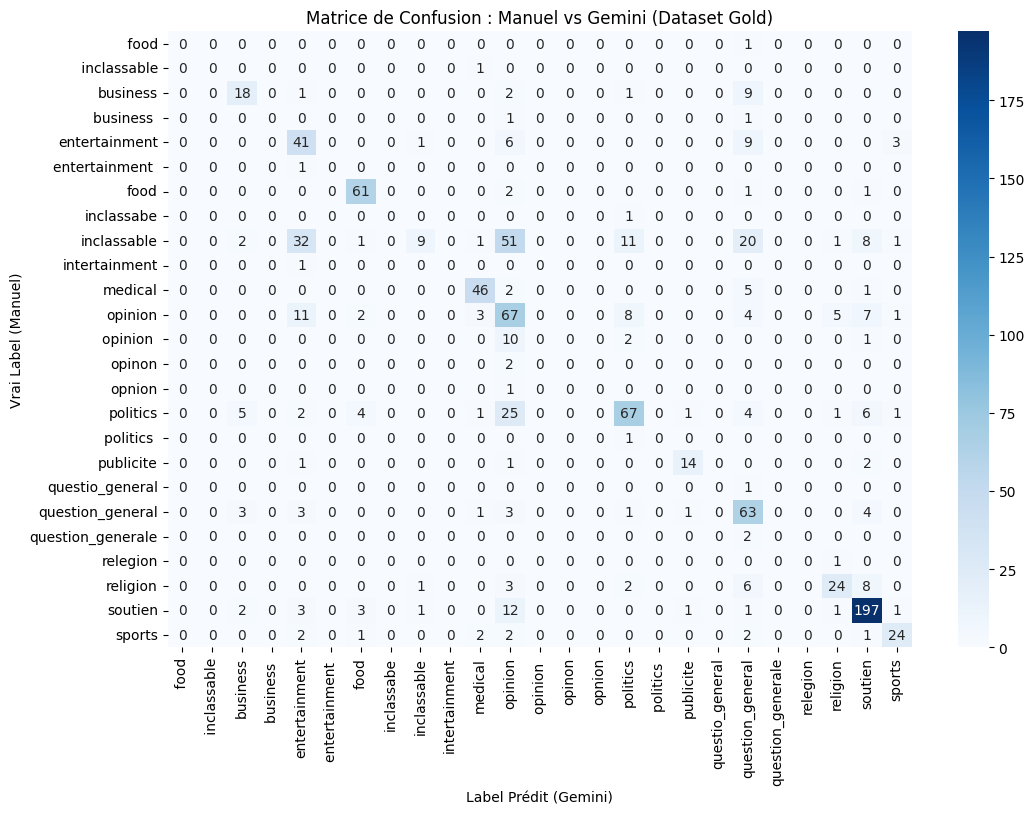

' \n# ---------------------------------------------------------\n# 4. ÉQUILIBRAGE DU DATASET FINAL (25 000 commentaires)\n# ---------------------------------------------------------\nprint(f"\n--- ÉQUILIBRAGE VERS LE DATASET FINAL ---")\nprint(f"Distribution actuelle (Total: {len(df_final)}) :")\nprint(df_final[\'label\'].value_counts())\n\n# Stratégie d\'équilibrage : On fixe un seuil pour les classes trop nombreuses\nSEUIL_MAX = 2000 \nbalanced_list = []\n\nfor label in df_final[\'label\'].unique():\n    subset = df_final[df_final[\'label\'] == label]\n    if len(subset) > SEUIL_MAX:\n        subset = subset.sample(n=SEUIL_MAX, random_state=42)\n    balanced_list.append(subset)\n\ndf_balanced = pd.concat(balanced_list).sample(frac=1).reset_index(drop=True)\n\nprint(f"\nDistribution après équilibrage (Total: {len(df_balanced)}) :")\nprint(df_balanced[\'label\'].value_counts())\n\n# Exportation\ndf_balanced.to_csv(\'dataset_darija_final_25k.csv\', index=False, encoding=\'utf-8-sig\')\n

In [7]:
# 1. CHARGEMENT DES DONNÉES
df_1000 = pd.read_csv('1000_gold_verifie.csv')
df_861 = pd.read_csv('861_verifie_clean.csv')

with open('mon_data_final.json', 'r', encoding='utf-8') as f:
    df_final = pd.DataFrame(json.load(f))

# ---------------------------------------------------------
# 2. CALCUL DES STATISTIQUES (COMBINÉES)
# ---------------------------------------------------------

# Analyse du fichier 1000_gold (Basé sur la différence de labels)
df_1000_clean = df_1000.dropna(subset=['gemini_label', 'manuel_label'])
total_1000 = len(df_1000_clean)
corrections = df_1000_clean[df_1000_clean['gemini_label'] != df_1000_clean['manuel_label']]  # labels Gemini corrigés à la main (utilisé plus bas)
corr_1000 = len(corrections)

# Analyse du fichier 861_clean (Basé sur la colonne decision)
total_861 = len(df_861)
corr_861 = len(df_861[df_861['decision'] == 'corriger'])

# Calculs globaux
total_verifie = total_1000 + total_861
total_corrections = corr_1000 + corr_861
taux_correction_global = (total_corrections / total_verifie) * 100
accuracy_globale = 100 - taux_correction_global

print(f"--- RÉSULTATS DU CONTRÔLE QUALITÉ (861 + 1000) ---")
print(f"Total des textes vérifiés : {total_verifie}")
print(f"Nombre total de corrections : {total_corrections}")
print(f"Taux de correction global : {taux_correction_global:.2f}%")
print(f"Précision globale (Accuracy) : {accuracy_globale:.2f}%")

# ---------------------------------------------------------
# 3. MATRICE DE CONFUSION (Sur le dataset Gold)
# ---------------------------------------------------------
# Note : Seul le fichier Gold contient les labels 'avant/après' pour la matrice
labels = sorted(list(set(df_1000_clean['manuel_label'].unique()) | set(df_1000_clean['gemini_label'].unique())))
cm = confusion_matrix(df_1000_clean['manuel_label'], df_1000_clean['gemini_label'], labels=labels)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.title('Matrice de Confusion : Manuel vs Gemini (Dataset Gold)')
plt.ylabel('Vrai Label (Manuel)')
plt.xlabel('Label Prédit (Gemini)')
plt.show()
''' 
# ---------------------------------------------------------
# 4. ÉQUILIBRAGE DU DATASET FINAL (25 000 commentaires)
# ---------------------------------------------------------
print(f"\n--- ÉQUILIBRAGE VERS LE DATASET FINAL ---")
print(f"Distribution actuelle (Total: {len(df_final)}) :")
print(df_final['label'].value_counts())

# Stratégie d'équilibrage : On fixe un seuil pour les classes trop nombreuses
SEUIL_MAX = 2000 
balanced_list = []

for label in df_final['label'].unique():
    subset = df_final[df_final['label'] == label]
    if len(subset) > SEUIL_MAX:
        subset = subset.sample(n=SEUIL_MAX, random_state=42)
    balanced_list.append(subset)

df_balanced = pd.concat(balanced_list).sample(frac=1).reset_index(drop=True)

print(f"\nDistribution après équilibrage (Total: {len(df_balanced)}) :")
print(df_balanced['label'].value_counts())

# Exportation
df_balanced.to_csv('dataset_darija_final_25k.csv', index=False, encoding='utf-8-sig')
print("\n✅ Fichier 'dataset_darija_final_25k.csv' généré avec succès.")" '''

# II. Analyse des Erreurs Spécifiques (Analyse Qualitative)
Liste des 10 premiers exemples où Gemini a échoué. Utile pour identifier les problèmes liés à la Darija.

In [4]:
print("--- FOCUS SUR LES ERREURS DE LA DARIJA ---")
erreurs_exemples = corrections[['text', 'gemini_label', 'manuel_label']].head(10)
for i, row in erreurs_exemples.iterrows():
    print(f"💬 TEXTE : {row['text']}")
    print(f"❌ GEMINI : {row['gemini_label']} | ✅ MANUEL : {row['manuel_label']}")
    print("-" * 50)

--- FOCUS SUR LES ERREURS DE LA DARIJA ---
💬 TEXTE : اسعار غالية
❌ GEMINI : politics | ✅ MANUEL : business
--------------------------------------------------
💬 TEXTE : ختي الله يشفيك عطي لراسك الراحة الصحة لا تشتري بتمن
❌ GEMINI : soutien | ✅ MANUEL : medical
--------------------------------------------------
💬 TEXTE : واش كيعاونوك اخوتك ولا والو
❌ GEMINI : question_general | ✅ MANUEL : inclassable
--------------------------------------------------
💬 TEXTE : سلام عافاك بغيت نسولك واش تاتاكلو هاد الشي كامل في الفطور
❌ GEMINI : question_general | ✅ MANUEL :  food
--------------------------------------------------
💬 TEXTE : مخلط معاه الخرطال عندك الحق
❌ GEMINI : opinion | ✅ MANUEL : food
--------------------------------------------------
💬 TEXTE : Bar7 dartu dart had tari9 chhar momkin khalih o nkhadm bih
❌ GEMINI : food | ✅ MANUEL : inclassable
--------------------------------------------------
💬 TEXTE : لا حول و لا قوة الا بالله رمضان العبادة ماشي البذخ حرام عليكم كاين اي ماعندوش اتقو ا

# III. Équilibrage du Dataset Final
Visualisation du déséquilibre et application d'un seuil pour rendre le dataset "propre" pour l'entraînement.

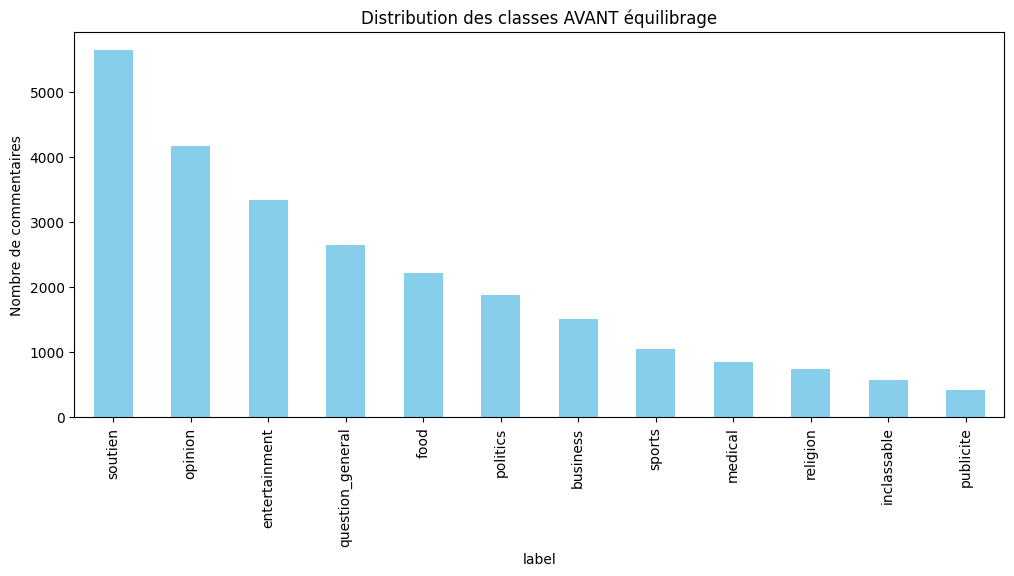

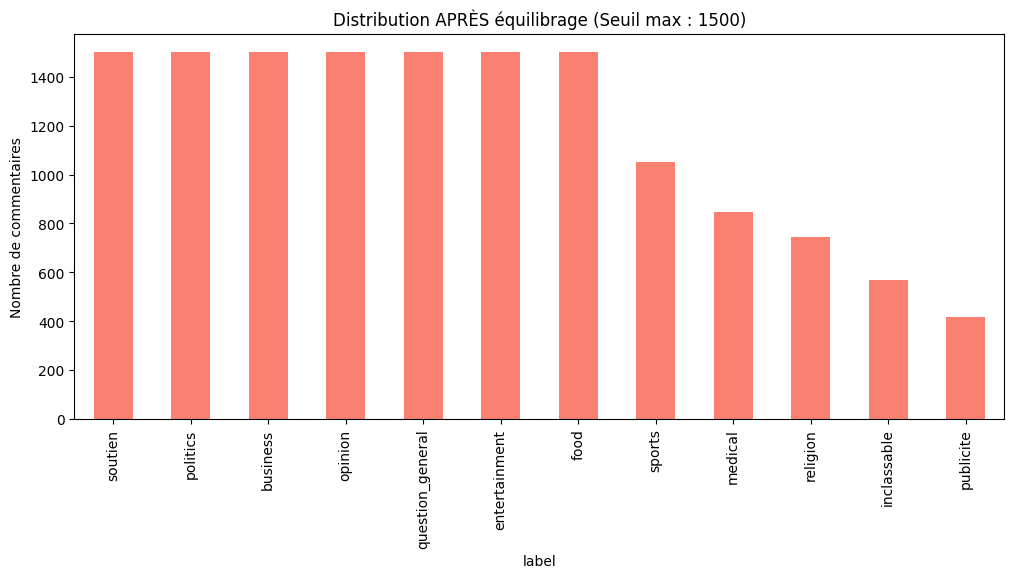

In [8]:
# 1. Visualisation de la distribution actuelle
plt.figure(figsize=(12, 5))
df_final['label'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Distribution des classes AVANT équilibrage')
plt.ylabel('Nombre de commentaires')
plt.show()

# 2. Application de l'équilibrage (Undersampling)
# On limite les classes trop grandes (comme 'soutien') pour ne pas biaiser le futur modèle
SEUIL_MAX = 1500 # Tu peux ajuster ce chiffre
balanced_list = []

for label in df_final['label'].unique():
    subset = df_final[df_final['label'] == label]
    if len(subset) > SEUIL_MAX:
        subset = subset.sample(n=SEUIL_MAX, random_state=42)
    balanced_list.append(subset)

df_balanced = pd.concat(balanced_list).sample(frac=1).reset_index(drop=True)

# 3. Visualisation après équilibrage
plt.figure(figsize=(12, 5))
df_balanced['label'].value_counts().plot(kind='bar', color='salmon')
plt.title(f'Distribution APRÈS équilibrage (Seuil max : {SEUIL_MAX})')
plt.ylabel('Nombre de commentaires')
plt.show()

# IV. Exportation du Dataset Propre
Sauvegarde du fichier final pour la phase d'entraînement du modèle.

In [9]:
# Sauvegarde en JSON et CSV
df_balanced.to_json('mon_data_25k_clean.json', orient='records', force_ascii=False, indent=2)
df_balanced.to_csv('mon_data_25k_clean.csv', index=False, encoding='utf-8-sig')

print(f"🚀 Terminé ! Le dataset contient maintenant {len(df_balanced)} lignes propres et équilibrées.")
print("Fichiers générés : 'mon_data_25k_clean.json' et 'mon_data_25k_clean.csv'")

🚀 Terminé ! Le dataset contient maintenant 14130 lignes propres et équilibrées.
Fichiers générés : 'mon_data_25k_clean.json' et 'mon_data_25k_clean.csv'


# NLP Augmentation
> Random Swap (RS) : Changer l'ordre de deux mots au hasard.

> Random Deletion (RD) : Supprimer un mot peu important au hasard (pour simuler les commentaires très courts).

> Synonym Replacement (SR) simplifié : Remplacer des mots très communs par leurs variantes en Darija (ex: "mzyan" par "khir", "chokran" par "barakallaho fik").

In [10]:
import pandas as pd
import json
import random

# 1. Chargement
with open('mon_data_final.json', 'r', encoding='utf-8') as f:
    df_final = pd.DataFrame(json.load(f))

# 2. Fonctions d'augmentation textuelle pure
def augment_text_only(text):
    words = text.split()
    if len(words) < 3:
        return text # Trop court pour être modifié
    
    choice = random.randint(1, 2)
    
    # Technique 1 : Inversion de mots (Random Swap)
    if choice == 1:
        words_list = list(words)
        idx1, idx2 = random.sample(range(len(words_list)), 2)
        words_list[idx1], words_list[idx2] = words_list[idx2], words_list[idx1]
        return " ".join(words_list)
    
    # Technique 2 : Suppression aléatoire (Random Deletion)
    # Simule un utilisateur qui écrit plus vite/court
    else:
        words_list = list(words)
        idx = random.randint(0, len(words_list) - 1)
        del words_list[idx]
        return " ".join(words_list)

# 3. Paramétrage pour atteindre 25 000
# Avec 12 classes, il faut environ 2084 lignes par classe
TARGET_PER_CLASS = 2084 
balanced_list = []

print("--- Augmentation en cours (Zéro Émojis) ---")

for label in df_final['label'].unique():
    subset = df_final[df_final['label'] == label]
    current_count = len(subset)
    
    if current_count >= TARGET_PER_CLASS:
        # Sous-échantillonnage pour les classes trop pleines
        new_subset = subset.sample(n=TARGET_PER_CLASS, random_state=42)
    else:
        # Augmentation pour les classes creuses
        needed = TARGET_PER_CLASS - current_count
        augmented_samples = []
        
        # On boucle jusqu'à atteindre la cible
        while len(augmented_samples) < needed:
            original_row = subset.sample(n=1).iloc[0]
            new_row = original_row.copy()
            
            # Application de la transformation
            new_row['text'] = augment_text_only(str(new_row['text']))
            
            # On évite d'ajouter un texte vide ou identique si possible
            if new_row['text'] != original_row['text']:
                new_row['id'] = f"{original_row['id']}_aug_{len(augmented_samples)}"
                augmented_samples.append(new_row)
            
            # Sécurité pour les classes très petites
            if len(augmented_samples) > needed: break

        new_subset = pd.concat([subset, pd.DataFrame(augmented_samples)])
    
    balanced_list.append(new_subset)
    print(f"Classe : {label.ljust(15)} | Final : {len(new_subset)}")

# 4. Assemblage final
df_25k = pd.concat(balanced_list).sample(frac=1, random_state=42).reset_index(drop=True)
df_25k = df_25k.head(25000) # Ajustement précis à 25k

print(f"\n✅ Dataset de {len(df_25k)} lignes prêt sans émojis.")

# 5. Exportation
df_25k.to_csv('dataset_darija_25k_text_only.csv', index=False, encoding='utf-8-sig')

--- Augmentation en cours (Zéro Émojis) ---
Classe : food            | Final : 2084
Classe : entertainment   | Final : 2084
Classe : soutien         | Final : 2084
Classe : opinion         | Final : 2084
Classe : question_general | Final : 2084
Classe : politics        | Final : 2084
Classe : business        | Final : 2084
Classe : sports          | Final : 2084
Classe : medical         | Final : 2084
Classe : religion        | Final : 2084
Classe : publicite       | Final : 2084
Classe : inclassable     | Final : 2084

✅ Dataset de 25000 lignes prêt sans émojis.
